<a href="https://colab.research.google.com/github/daong0406/2026-Linear-Algebra/blob/main/%EA%B3%BC%EC%A0%9C)_ex02_transform_tiefighter_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [258]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [259]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [260]:
def draw_rectangle(ax, p1, p2, p3, p4, color=None):
  if color:
        my_polygon = Polygon([p1, p2, p3, p4], color=color)
  else:
        my_polygon = Polygon([p1, p2, p3, p4])
  ax.add_patch(my_polygon)

In [261]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_rectangle(ax, p1, p2, p3, p4)

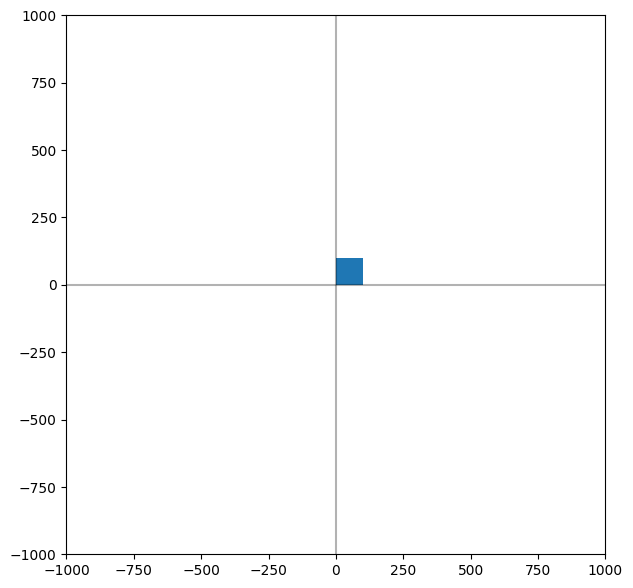

In [262]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()

### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta)  
* scale(p, sx, sy)  
* shear_x(p, sx)  
* shear_y(p, sy)  
* reflect_x(p)  
* reflect_y(p)   
* ...

In [263]:
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p1
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [264]:
def rotate(p,theta):

  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 회전 변환 행렬 생성
  m = np.array([[np.cos(theta),-np.sin(theta),0.0],
              [np.sin(theta),np.cos(theta), 0.0],
              [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [265]:
def scale(p, sx, sy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 크기 변환 행렬 생성
  m = np.array([[sx, 0.0, 0.0], [0.0, sy, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [266]:
def shear_x(p,sx):

  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 기울기(x) 변환 행렬 생성
  m = np.array([[1.0, sx, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [267]:
def shear_y(p,sy):


  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 기울기(y) 변환 행렬 생성
  m = np.array([[1.0, 0.0, 0.0], [sy, 1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [268]:
def reflect_x(p):

  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 반전 변환 행렬 생성
  m = np.array([[-1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [269]:
def reflect_y(p):

    hp = np.array([p[0], p[1], 1.0])
    m = np.array([
        [-1.0, 0.0, 0.0],
        [ 0.0, 1.0, 0.0],
        [ 0.0, 0.0, 1.0]
    ])
    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q

In [270]:
def reflect_origin(p):
    # 원점 대칭
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([
        [-1.0,  0.0, 0.0],
        [ 0.0, -1.0, 0.0],
        [ 0.0,  0.0, 1.0]
    ])
    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q

In [271]:
def reflect_y_eq_x(p):
    # y = x 대칭
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([
        [0.0, 1.0, 0.0],
        [1.0, 0.0, 0.0],
        [0.0, 0.0, 1.0]
    ])
    q = np.dot(m, hp)
    q = np.array([q[0], q[1]])
    return q

#### 2. 파트 그리기
* draw_cockpit(p1, p2, p3, p4)    # 중앙 조종석
* draw_left_arm(p1, p2, p3, p4)   # 왼쪽 날개축
* draw_left_wing(p1, p2, p3, p4)  # 왼쪽 날개
* draw_right_arm(p1, p2, p3, p4)  # 오른쪽 날개축
* draw_right_wing(p1, p2, p3, p4) # 오른쪽 날개

In [272]:
def draw_cockpit(ax, p1, p2, p3, p4):  # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  # q = T(-LEN/2, -LEN/2)p
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)


  # 2. 크기 변환: S(5, 5)
  s = 5
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)

  # 3. 회전 변환: R(pi/4)
  q1 = rotate(q1, 3.14/4.0)
  q2 = rotate(q2, 3.14/4.0)
  q3 = rotate(q3, 3.14/4.0)
  q4 = rotate(q4, 3.14/4.0)


  # 4. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [273]:
def draw_right_arm_top(ax, p1, p2, p3, p4):

    # 1. 원점으로 이동
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    # 2. 가로로 길고 얇게 크기 변환
    q1 = scale(q1, 5.0, 0.5)
    q2 = scale(q2, 5.0, 0.5)
    q3 = scale(q3, 5.0, 0.5)
    q4 = scale(q4, 5.0, 0.5)

    # 3. y축 방향으로 기울이기
    q1 = shear_y(q1, -0.1)
    q2 = shear_y(q2, -0.1)
    q3 = shear_y(q3, -0.1)
    q4 = shear_y(q4, -0.1)

    # 3. 오른쪽으로 이동
    q1 = translate(q1, 500, 25)
    q2 = translate(q2, 500, 25)
    q3 = translate(q3, 500, 25)
    q4 = translate(q4, 500, 25)

    draw_rectangle(ax, q1, q2, q3, q4)


# 오른쪽 아래쪽 날개축 막대
def draw_right_arm_bottom(ax, p1, p2, p3, p4):

    # 1. 원점으로 이동
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    # 2. 가로로 길고 얇게 크기 변환
    q1 = scale(q1, 5.0, 0.5)
    q2 = scale(q2, 5.0, 0.5)
    q3 = scale(q3, 5.0, 0.5)
    q4 = scale(q4, 5.0, 0.5)

    # 3. y축 방향으로 기울이기..
    q1 = shear_y(q1, 0.1)
    q2 = shear_y(q2, 0.1)
    q3 = shear_y(q3, 0.1)
    q4 = shear_y(q4, 0.1)

    # 3. 오른쪽 아래로 이동
    q1 = translate(q1, 500, -25)
    q2 = translate(q2, 500, -25)
    q3 = translate(q3, 500, -25)
    q4 = translate(q4, 500, -25)

    draw_rectangle(ax, q1, q2, q3, q4)

In [274]:
def draw_right_wing(ax, p1, p2, p3, p4):  # 오른쪽 날개
    # 1. 원점으로 이동
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    # 2. 크기 변환
    q1 = scale(q1, 1.0, 10.0)
    q2 = scale(q2, 1.0, 10.0)
    q3 = scale(q3, 1.0, 10.0)
    q4 = scale(q4, 1.0, 10.0)

    # 3. y축 방향 기울기
    q1 = shear_y(q1, 0.4)
    q2 = shear_y(q2, 0.4)
    q3 = shear_y(q3, 0.4)
    q4 = shear_y(q4, 0.4)

    # 4. 오른쪽 날개 위치로 이동
    q1 = translate(q1, 800, 0)
    q2 = translate(q2, 800, 0)
    q3 = translate(q3, 800, 0)
    q4 = translate(q4, 800, 0)

    draw_rectangle(ax, q1, q2, q3, q4)

In [275]:
# 왼쪽 위쪽 날개축 막대
def draw_left_arm_top(ax, p1, p2, p3, p4):

    # 오른쪽 위쪽 막대와 같은 변환
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    q1 = scale(q1, 5.0, 0.5)
    q2 = scale(q2, 5.0, 0.5)
    q3 = scale(q3, 5.0, 0.5)
    q4 = scale(q4, 5.0, 0.5)

    # 3. y축 방향으로 기울이기
    q1 = shear_y(q1, -0.1)
    q2 = shear_y(q2, -0.1)
    q3 = shear_y(q3, -0.1)
    q4 = shear_y(q4, -0.1)

    q1 = translate(q1, 500, 25)
    q2 = translate(q2, 500, 25)
    q3 = translate(q3, 500, 25)
    q4 = translate(q4, 500, 25)

    # y축 대칭
    q1 = reflect_y(q1)
    q2 = reflect_y(q2)
    q3 = reflect_y(q3)
    q4 = reflect_y(q4)

    draw_rectangle(ax, q1, q2, q3, q4)


# 왼쪽 아래쪽 날개축 막대
def draw_left_arm_bottom(ax, p1, p2, p3, p4):

    # 오른쪽 아래쪽 막대와 같은 변환
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    q1 = scale(q1, 5.0, 0.5)
    q2 = scale(q2, 5.0, 0.5)
    q3 = scale(q3, 5.0, 0.5)
    q4 = scale(q4, 5.0, 0.5)

    # 3. y축 방향으로 기울이기
    q1 = shear_y(q1, 0.1)
    q2 = shear_y(q2, 0.1)
    q3 = shear_y(q3, 0.1)
    q4 = shear_y(q4, 0.1)

    q1 = translate(q1, 500, -25)
    q2 = translate(q2, 500, -25)
    q3 = translate(q3, 500, -25)
    q4 = translate(q4, 500, -25)

    # y축 대칭
    q1 = reflect_y(q1)
    q2 = reflect_y(q2)
    q3 = reflect_y(q3)
    q4 = reflect_y(q4)

    draw_rectangle(ax, q1, q2, q3, q4)

In [276]:
# 오른쪽 사다리꼴 날개
def draw_right_wing(ax, p1, p2, p3, p4):

    # 1. 원점으로 이동
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    # 2. 세로로 길게 크기 변환
    q1 = scale(q1, 1.0, 8.0)
    q2 = scale(q2, 1.0, 8.0)
    q3 = scale(q3, 1.0, 8.0)
    q4 = scale(q4, 1.0, 8.0)

    # 3. 오른쪽으로 이동
    q1 = translate(q1, 800, 0)
    q2 = translate(q2, 800, 0)
    q3 = translate(q3, 800, 0)
    q4 = translate(q4, 800, 0)

    # 4. 위아래 모서리를 조절하여 사다리꼴 생성
    q2 = translate(q2, 0, -200)
    q3 = translate(q3, 0, 200)

    draw_rectangle(ax, q1, q2, q3, q4)


# 왼쪽 사다리꼴 날개
def draw_left_wing(ax, p1, p2, p3, p4):

    # 오른쪽 날개와 같은 변환
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    q1 = scale(q1, 1.0, 8.0)
    q2 = scale(q2, 1.0, 8.0)
    q3 = scale(q3, 1.0, 8.0)
    q4 = scale(q4, 1.0, 8.0)

    q1 = translate(q1, 800, 0)
    q2 = translate(q2, 800, 0)
    q3 = translate(q3, 800, 0)
    q4 = translate(q4, 800, 0)

    q2 = translate(q2, 0, -200)
    q3 = translate(q3, 0, 200)

    # y축 대칭
    q1 = reflect_y(q1)
    q2 = reflect_y(q2)
    q3 = reflect_y(q3)
    q4 = reflect_y(q4)

    draw_rectangle(ax, q1, q2, q3, q4)

In [277]:
# 2. tiefigher 그리기
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 1. 중앙 조종석
  draw_cockpit(ax, p1, p2, p3, p4)

  # 2. 좌우 날개축 막대 4개
  draw_right_arm_top(ax, p1, p2, p3, p4)
  draw_right_arm_bottom(ax, p1, p2, p3, p4)
  draw_left_arm_top(ax, p1, p2, p3, p4)
  draw_left_arm_bottom(ax, p1, p2, p3, p4)

  # 3. 좌우 사다리꼴 날개
  draw_right_wing(ax, p1, p2, p3, p4)
  draw_left_wing(ax, p1, p2, p3, p4)

### 3. main

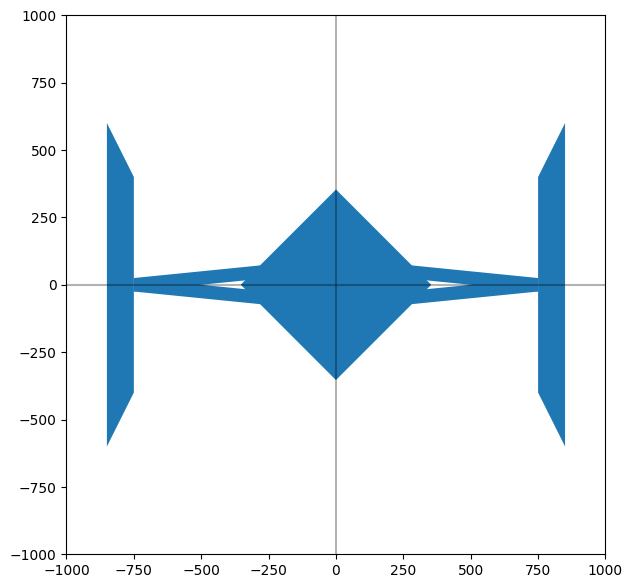

In [278]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()